# RAG Retrieval Optimization & Evaluation

Xinyi Ping

Nov 2026

In [158]:
import numpy as np
import pandas as pd
from beir import util
from beir.datasets.data_loader import GenericDataLoader
from rank_bm25 import BM25Okapi
import re
from sentence_transformers import SentenceTransformer
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import defaultdict
from sentence_transformers import CrossEncoder
import time
import json
import matplotlib.pyplot as plt

## Dataset Loading and Exploration

In [ ]:
# load data

corpus, queries, qrels = GenericDataLoader(data_folder="data/scifact").load(split="train")

print("Documents:", len(corpus))
print("Queries:", len(queries))
print("Labeled queries:", len(qrels))

# load original train labels
df = pd.read_csv("data/scifact/qrels/train.tsv", sep="\t")

# split by query ID
query_ids = df["query-id"].unique()
train_ids, dev_ids = train_test_split(query_ids, test_size=0.2, random_state=42)

train_df = df[df["query-id"].isin(train_ids)]
dev_df = df[df["query-id"].isin(dev_ids)]

# save new splits
train_df.to_csv("data/scifact/qrels/train_split.tsv", sep="\t", index=False)
dev_df.to_csv("data/scifact/qrels/dev.tsv", sep="\t", index=False)

print("\nTrain queries:", len(train_ids))
print("Dev queries:", len(dev_ids))

# load train split
_, train_queries, train_qrels = GenericDataLoader(data_folder="data/scifact").load(split="train_split")

# load dev split
_, dev_queries, dev_qrels = GenericDataLoader(data_folder="data/scifact").load(split="dev")

print("\nTrain queries:", len(train_queries))
print("Dev queries:", len(dev_queries))

# check if overlap
assert not (set(train_qrels.keys()) & set(dev_qrels.keys()))
print("\nNo query overlap")

eval_queries = dev_queries
eval_qrels = dev_qrels

  0%|          | 0/5183 [00:00<?, ?it/s]

Documents: 5183
Queries: 809
Labeled queries: 809

Train queries: 647
Dev queries: 162


  0%|          | 0/5183 [00:00<?, ?it/s]

  0%|          | 0/5183 [00:00<?, ?it/s]


Train queries: 647
Dev queries: 162

No query overlap


In [90]:
# check the dataset

# Check corpus
doc_id = next(iter(corpus))

print("Document ID:", doc_id)
print("Document:", corpus[doc_id])

# Check train split
train_query_id = next(iter(train_qrels))

print("\nTrain Query ID:", train_query_id)
print("Train Query:", train_queries[train_query_id])
print("Relevant documents:", train_qrels[train_query_id])

# Check dev split
dev_query_id = next(iter(dev_qrels))

print("\nDev Query ID:", dev_query_id)
print("Dev Query:", dev_queries[dev_query_id])
print("Relevant documents:", dev_qrels[dev_query_id])

#check if disjoint
train_ids = set(train_qrels.keys())
dev_ids = set(dev_qrels.keys())

assert train_ids.isdisjoint(dev_ids)
print("\nTrain and Dev are disjoint")

Document ID: 4983
Document: {'text': 'Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabilities. A line scan diffusion-weighted magnetic resonance imaging (MRI) sequence with diffusion tensor analysis was applied to measure the apparent diffusion coefficient, to calculate relative anisotropy, and to delineate three-dimensional fiber architecture in cerebral white matter in preterm (n = 17) and full-term infants (n = 7). To assess effects of prematurity on cerebral white matter development, early gestation preterm infants (n = 10) were studied a second time at term. In the central white matter the mean apparent diffusion coefficient at 28 wk was high, 1.8 microm2/ms, and decreased toward term to 1.2 microm2/ms. In the posterior limb of the internal capsule, the mean apparent diffusion coefficients at both times were similar (1.2 versus 1.1 microm2/ms). Relative anisotropy was higher the cl

## 1. BM25 Retrieval

Goal: Given query, find the 5 most relevant documents, then check if the search is correct.

In [91]:
#tokenization
def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

doc_ids = list(corpus.keys())

documents = [corpus[doc_id]["title"] + " " +corpus[doc_id]["text"]
    for doc_id in doc_ids]

tokenized_docs = [tokenize(doc) for doc in documents]

print("Number of documents:", len(documents))
print("First document tokens:", tokenized_docs[0][:15])

Number of documents: 5183
First document tokens: ['microstructural', 'development', 'of', 'human', 'newborn', 'cerebral', 'white', 'matter', 'assessed', 'in', 'vivo', 'by', 'diffusion', 'tensor', 'magnetic']


In [92]:
# create BM25 index
bm25 = BM25Okapi(tokenized_docs)

In [98]:
#search 5 most relevant doc and check if search is correct
query_id = next(iter(qrels.keys()))
query = queries[query_id]
print("Query:", query)

#calculate BM25 scores
scores = bm25.get_scores(tokenize(query))

#find 5 most relevant doc indices
top_indices = scores.argsort()[::-1][:5]

for rank, i in enumerate(top_indices, start=1):
    doc_id = doc_ids[i]

    print(f"\nRank {rank}")
    print("Doc ID:", doc_id)
    print("BM25 Score:", scores[i])
    print("Title:", corpus[doc_id]["title"])
    print("Relevant:", doc_id in qrels[test_qid])

Query: 0-dimensional biomaterials lack inductive properties.

Rank 1
Doc ID: 10608397
BM25 Score: 10.173663486906072
Title: High-performance neuroprosthetic control by an individual with tetraplegia.
Relevant: False

Rank 2
Doc ID: 40212412
BM25 Score: 9.556998622831742
Title: Periosteal bone formation--a neglected determinant of bone strength.
Relevant: False

Rank 3
Doc ID: 825728
BM25 Score: 9.318007633232618
Title: Metastatic colonization requires the repression of the epithelial-mesenchymal transition inducer Prrx1.
Relevant: False

Rank 4
Doc ID: 4435369
BM25 Score: 9.226124341365532
Title: Extracellular vesicles for drug delivery.
Relevant: False

Rank 5
Doc ID: 28138927
BM25 Score: 9.026305440159078
Title: Potent, Selective, and Orally Bioavailable Inhibitors of VPS34 Provide Chemical Tools to Modulate Autophagy in Vivo.
Relevant: False


In [99]:
#check why BM25 is false
relevant_doc_id = "31715818"

print("Document exists:", relevant_doc_id in corpus)

if relevant_doc_id in corpus:
    print("Title:", corpus[relevant_doc_id]["title"])
    print("Text:", corpus[relevant_doc_id]["text"][:500])

relevant_doc_id = "31715818"

query = queries[query_id]
scores = bm25.get_scores(tokenize(query))

sorted_indices = np.argsort(scores)[::-1]

if relevant_doc_id in doc_ids:
    relevant_index = doc_ids.index(relevant_doc_id)

    rank = np.where(sorted_indices == relevant_index)[0][0] + 1

    print("Query:", query)
    print("Relevant Document Rank:", rank)
    print("Relevant Document Score:", scores[relevant_index])

print("\nQUERY:")
print(queries[query_id])

print("\nRELEVANT DOCUMENT:")
print(corpus["31715818"]["title"])
print(corpus["31715818"]["text"][:1000])

Document exists: True
Title: New opportunities: the use of nanotechnologies to manipulate and track stem cells.
Text: Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo tracking; nanoparticles, carbon nanotubes, and polyplexes for the intracellular delivery of genes/oligonucleotides and protein/peptides; and engineered nanometer-scale scaffolds for stem cell differentiation and transplantation. This review examines the use of nanotechnologies for stem ce
Query: 0-dimensional biomaterials lack inductive properties.
Relevant Document Rank: 1895
Relevant Document Score: 0.0

QUERY:
0-dimensional biomaterials lack inductive properties.

RELEVANT DOCUMENT:
New opportunities: the use of nanotechnologies to manipulate and track stem cells.
Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and man

In [100]:
# Select the query whose relevant document is 31715818
target_doc_id = "31715818"

target_qid = next(
    qid for qid, rels in qrels.items()
    if target_doc_id in rels and rels[target_doc_id] > 0
)

# Recalculate everything for the same query
target_query = queries[target_qid]
target_scores = bm25.get_scores(tokenize(target_query))

target_doc = corpus[target_doc_id]
target_doc_text = (target_doc["title"] + " " +target_doc["text"])

query_tokens = set(tokenize(target_query))
doc_tokens = set(tokenize(target_doc_text))

target_index = doc_ids.index(target_doc_id)

print("Query ID:", target_qid)
print("Query:", target_query)
print("Relevant Document ID:", target_doc_id)

print("\nQuery tokens:", query_tokens)
print("Common tokens:", query_tokens & doc_tokens)
print("BM25 Score:", target_scores[target_index])

Query ID: 0
Query: 0-dimensional biomaterials lack inductive properties.
Relevant Document ID: 31715818

Query tokens: {'dimensional', 'inductive', 'biomaterials', '0', 'properties', 'lack'}
Common tokens: set()
BM25 Score: 0.0


In [101]:
doc_ids = list(corpus.keys())

documents = [corpus[doc_id]["title"] + " " + corpus[doc_id]["text"]
    for doc_id in doc_ids]

In [102]:
#BM25 retrieval function
def bm25_retrieve(query, k=20):
    scores = bm25.get_scores(tokenize(query))
    top_indices = np.argsort(scores)[::-1][:k]
    return [doc_ids[i] for i in top_indices]

In [131]:
#recall calculation function
def recall_k(retrieved_ids, relevant_ids, k=5):
    relevant = set(relevant_ids)

    if not relevant:
        return 0.0

    retrieved = set(retrieved_ids[:k])
    return len(retrieved & relevant) / len(relevant)

In [132]:
#calculat recall
k_values = [5, 10, 20]
results = {k: [] for k in k_values}

for qid, rels in qrels.items():
    retrieved = bm25_retrieve(queries[qid], k=20)

    relevant = [doc_id
        for doc_id, score in rels.items()
        if score > 0
    ]

    for k in k_values:
        results[k].append(recall_k(retrieved, relevant, k))

for k in k_values:
    print(f"BM25 Recall@{k}: {np.mean(results[k]):.4f}")

BM25 Recall@5: 0.7168
BM25 Recall@10: 0.7837
BM25 Recall@20: 0.8273


In [104]:
#error case
error_case = {
    "query_id": "0",
    "query": target_query,
    "relevant_doc_id": "31715818",
    "bm25_score": 0.0,
    "lexical_overlap": 0,
    "error_type": "Lexical Mismatch"
}

## 2. Dense Retrieval

Goal: find the 5 most relevant documents, then check if the search is correct.

In [105]:
# sentence transformer
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

print("Model loaded!")
print("Embedding dimension:", model.get_sentence_embedding_dimension())
print("Maximum sequence length:", model.max_seq_length)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded!
Embedding dimension: 384
Maximum sequence length: 256


C:\Users\ASUS\AppData\Local\Temp\ipykernel_28568\2521332875.py:5: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", model.get_sentence_embedding_dimension())


In [106]:
#embedding
embedding_dir = Path("data/embeddings")
embedding_dir.mkdir(parents=True, exist_ok=True)

embedding_path = embedding_dir / "scifact_minilm.npy"
doc_ids_path = embedding_dir / "scifact_doc_ids.npy"

if embedding_path.exists() and doc_ids_path.exists():
    saved_ids = np.load(doc_ids_path).tolist()
    if saved_ids != doc_ids:
        raise ValueError("Document IDs changed. Regenerate embeddings.")
    doc_embeddings = np.load(embedding_path)
    print("Loaded saved embeddings.")

else:
    doc_embeddings = model.encode_document(
        documents,
        batch_size=16,
        normalize_embeddings=True,
        show_progress_bar=True
    )
    np.save(embedding_path, doc_embeddings)
    np.save(doc_ids_path, np.array(doc_ids))

    print("Embeddings generated and saved.")
print("Embedding shape:", doc_embeddings.shape)

Loaded saved embeddings.
Embedding shape: (5183, 384)


In [107]:
#dense retrieval function
def dense_retrieve(query, k=20):

    # Encode query
    query_embedding = model.encode_query([query], normalize_embeddings=True)

    # Compute similarity scores
    scores = (query_embedding @ doc_embeddings.T)[0]

    # Find top-k documents
    top_indices = np.argsort(scores)[::-1][:k]

    return [doc_ids[i] for i in top_indices]

In [108]:
#find 5 most relevant doc and check if search is correct
query_id = "0"
query = queries[query_id]

retrieved = dense_retrieve(query, k=5)
relevant_docs = {doc_id
    for doc_id, score in qrels[query_id].items()
    if score > 0
}
print("Query:", query)

for rank, doc_id in enumerate(retrieved, start=1):
    print(f"\nRank {rank}")
    print("Document ID:", doc_id)
    print("Title:", corpus[doc_id]["title"])
    print("Relevant:", doc_id in relevant_docs)

Query: 0-dimensional biomaterials lack inductive properties.

Rank 1
Document ID: 29638116
Title: Complex Tissue and Disease Modeling using hiPSCs.
Relevant: False

Rank 2
Document ID: 4346436
Title: Nonlinear Elasticity in Biological Gels
Relevant: False

Rank 3
Document ID: 17388232
Title: Mechanical regulation of cell function with geometrically modulated elastomeric substrates
Relevant: False

Rank 4
Document ID: 31715818
Title: New opportunities: the use of nanotechnologies to manipulate and track stem cells.
Relevant: True

Rank 5
Document ID: 927561
Title: Emergent structures and dynamics of cell colonies by contact inhibition of locomotion
Relevant: False


In [133]:
#calculate recall
k_values = [5, 10, 20]

eval_query_ids = list(qrels.keys())
eval_query_texts = [queries[qid] for qid in eval_query_ids]

query_embeddings = model.encode_query(
    eval_query_texts,
    batch_size=16,
    normalize_embeddings=True,
    show_progress_bar=True
)

dense_results = {k: [] for k in k_values}

for idx, qid in enumerate(eval_query_ids):

    scores = query_embeddings[idx] @ doc_embeddings.T

    top_indices = np.argsort(scores)[::-1][:20]
    retrieved_ids = [doc_ids[i] for i in top_indices]

    relevant_ids = [doc_id
        for doc_id, relevance in qrels[qid].items()
        if relevance > 0
    ]

    for k in k_values:
        dense_results[k].append(recall_k(retrieved_ids, relevant_ids, k))

for k in k_values:
    print(f"Dense Recall@{k}: "f"{np.mean(dense_results[k]):.4f}")

Batches:   0%|          | 0/51 [00:00<?, ?it/s]

Dense Recall@5: 0.7347
Dense Recall@10: 0.7856
Dense Recall@20: 0.8424


In [110]:
#experimental records
experiment_config = {
    "dataset": "SciFact",
    "split": "train",
    "bm25": "BM25Okapi",
    "dense_model": "sentence-transformers/all-MiniLM-L6-v2",
    "normalize_embeddings": True,
    "k_values": [5, 10, 20]
}

## 3. Hybrid retrieval

Goal: find the 5 most relevant documents

In [111]:
# reciprocal rank dusion function
def reciprocal_rank_fusion(ranked_lists, c=60):
    rrf_scores = defaultdict(float)

    for ranked_docs in ranked_lists:
        for rank, doc_id in enumerate(ranked_docs, start=1):
            rrf_scores[doc_id] += 1 / (c + rank)

    fused_docs = sorted(
        rrf_scores,
        key=lambda doc_id: (-rrf_scores[doc_id], str(doc_id))
    )

    return fused_docs

In [53]:
# hybrid retrieval function
def hybrid_retrieve(query, k=20, candidate_k=100, c=60):

    # Retrieve candidates from BM25
    bm25_docs = bm25_retrieve(
        query,
        k=candidate_k
    )

    # Retrieve candidates from Dense
    dense_docs = dense_retrieve(
        query,
        k=candidate_k
    )

    # Fuse the rankings
    fused_docs = reciprocal_rank_fusion(
        [bm25_docs, dense_docs],
        c=c
    )

    return fused_docs[:k]

In [113]:
#find 5 most relevant doc
test_qid = next(iter(qrels))
test_query = queries[test_qid]

hybrid_docs = hybrid_retrieve(
    test_query,
    k=5,
    candidate_k=100
)

print("Query:", test_query)

for rank, doc_id in enumerate(hybrid_docs, start=1):
    print(f"\nRank {rank}")
    print("Document ID:", doc_id)
    print("Title:", corpus[doc_id]["title"])

Query: 0-dimensional biomaterials lack inductive properties.

Rank 1
Document ID: 40212412
Title: Periosteal bone formation--a neglected determinant of bone strength.

Rank 2
Document ID: 43385013
Title: Epithelial and mesenchymal subpopulations within normal basal breast cell lines exhibit distinct stem cell/progenitor properties.

Rank 3
Document ID: 803312
Title: Cerebral organoids model human brain development and microcephaly

Rank 4
Document ID: 4435369
Title: Extracellular vesicles for drug delivery.

Rank 5
Document ID: 25404036
Title: Three-Dimensional Modeling and Quantitative Analysis of Gap Junction Distributions in Cardiac Tissue


In [114]:
# compare BM25, dense, hybird
bm25_docs = bm25_retrieve(test_query, k=100)
dense_docs = dense_retrieve(test_query, k=100)
hybrid_docs = reciprocal_rank_fusion([bm25_docs, dense_docs])[:5]

print("BM25 Top 5:", bm25_docs[:5])
print("Dense Top 5:", dense_docs[:5])
print("Hybrid Top 5:", hybrid_docs)

BM25 Top 5: ['10608397', '40212412', '825728', '4435369', '28138927']
Dense Top 5: ['29638116', '4346436', '17388232', '31715818', '927561']
Hybrid Top 5: ['40212412', '43385013', '803312', '4435369', '25404036']


In [115]:
# RRF score calculation function
def RRF_score(doc_id, ranked_lists, c=60):
    score = 0.0

    for ranked_docs in ranked_lists:
        if doc_id in ranked_docs:
            rank = ranked_docs.index(doc_id) + 1
            score += 1 / (c + rank)

    return score

#get relevant doc 31715818 RRF score
print(
    "Relevant doc (31715818) RRF score:",
    RRF_score(target_doc_id, [bm25_docs, dense_docs])
)

Relevant doc (31715818) RRF score: 0.015625


In [116]:
#record error case
error_case = {
    "query_id": "0",
    "relevant_doc_id": "31715818",
    "dense_rank": 4,
    "rrf_score": 0.015625,
    "error_type": "Rank Fusion Suppression"
}

## 4. Cross-Encoder reranking

Goal: find the 5 most relevant documents, then check if the search is correct.

In [117]:
#sentence transformer
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L6-v2")


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

In [177]:
#cross encoder reranking function
def rerank_retrieve(query, k=20, candidate_k=100, c=60, return_scores=False):
    # retrieve candidates
    candidate_ids = hybrid_retrieve(
        query, k=candidate_k, candidate_k=candidate_k, c=c
    )

    # create (query, document) pairs
    pairs = [
        (query, corpus[doc_id]["title"] + " " + corpus[doc_id]["text"])
        for doc_id in candidate_ids
    ]

    # predict relevance scores
    scores = reranker.predict(
        pairs, batch_size=16, show_progress_bar=False
    )

    # sort documents by score
    top_indices = np.argsort(scores)[::-1][:k]
    ranked_ids = [candidate_ids[i] for i in top_indices]

    if return_scores:
        ranked_scores = [float(scores[i]) for i in top_indices]
        return ranked_ids, ranked_scores

    return ranked_ids

In [140]:
#find 5 most relevant doc
test_qid = next(iter(dev_qrels))
test_query = dev_queries[test_qid]

reranked_docs, scores = rerank_retrieve(
    test_query, k=5, candidate_k=100, return_scores=True
)

print("Query:", test_query)

for rank, (doc_id, score) in enumerate(zip(reranked_docs, scores), start=1):
    print(f"\nRank {rank}")
    print("Doc ID:", doc_id)
    print("Score:", score)
    print("Title:", corpus[doc_id]["title"])
    print("Relevant:", dev_qrels[test_qid].get(doc_id, 0) > 0)

Query: 1-1% of colorectal cancer patients are diagnosed with regional or distant metastases.

Rank 1
Doc ID: 10958594
Score: 3.974902629852295
Title: Nationwide trends in incidence, treatment and survival of colorectal cancer patients with synchronous metastases
Relevant: False

Rank 2
Doc ID: 23639838
Score: 1.3268098831176758
Title: Surgical Resection for Patients with Solid Brain Metastases: Current Status
Relevant: False

Rank 3
Doc ID: 1387104
Score: 1.2481811046600342
Title: Malignancies, prothrombotic mutations, and the risk of venous thrombosis.
Relevant: False

Rank 4
Doc ID: 18062308
Score: 0.6774600744247437
Title: Operable non-small cell lung cancer diagnosed by transpleural techniques : do they affect relapse and prognosis?
Relevant: False

Rank 5
Doc ID: 24980622
Score: 0.45629021525382996
Title: Hypoxia in relation to vasculature and proliferation in liver metastases in patients with colorectal cancer.
Relevant: False


In [144]:
#check relevant doc 31715818
target_qid = "0"
target_doc_id = "31715818"
target_query = queries[target_qid]

reranked_docs = rerank_retrieve(target_query, k=100, candidate_k=100)

if target_doc_id in reranked_docs:
    print("Reranked position:", reranked_docs.index(target_doc_id) + 1)
else:
    print("Not in Hybrid Top 100 candidates.")

Reranked position: 93


## Unified retrieval evaluation

Compare:

BM25 - BM25Okapi

dense - all-MiniLM-L6-v2

hybird - BM25 + dense + RRF, c = 60

hybird + reranker - hybird top 100 + MS MARCO cross-encoder

In [123]:
#load dev set
print("Train queries:", len(train_qrels))
print("Dev queries:", len(dev_qrels))

assert set(train_qrels).isdisjoint(set(dev_qrels))
assert set(dev_qrels).issubset(set(dev_queries))

Train queries: 647
Dev queries: 162


In [126]:
# ndcg calculation function
def ndcg_k(retrieved_ids, relevance_dict, k=10):
    gains = [
        relevance_dict.get(doc_id, 0)
        for doc_id in retrieved_ids[:k]
    ]

    dcg = sum(
        (2 ** rel - 1) / np.log2(rank + 1)
        for rank, rel in enumerate(gains, start=1)
    )

    ideal_rels = sorted(
        relevance_dict.values(),
        reverse=True
    )[:k]

    idcg = sum(
        (2 ** rel - 1) / np.log2(rank + 1)
        for rank, rel in enumerate(ideal_rels, start=1)
    )

    return dcg / idcg if idcg > 0 else 0.0

In [127]:
# reciprocal rank function
def reciprocal_rank_k(retrieved_ids, relevant_ids, k=10):
    relevant = set(relevant_ids)

    for rank, doc_id in enumerate(retrieved_ids[:k], start=1):
        if doc_id in relevant:
            return 1 / rank

    return 0.0

In [147]:
# evaluate function
def evaluate_retriever(name, retrieve_fn, queries, qrels):
    records = []
    rankings = {}

    for qid, rels in qrels.items():
        query = queries[qid]

        # Measure latency
        start = time.perf_counter()
        retrieved = retrieve_fn(query)
        latency_ms = (time.perf_counter() - start) * 1000

        # Ground truth
        relevant_ids = {
            doc_id
            for doc_id, relevance in rels.items()
            if relevance > 0
        }

        # Save metrics
        records.append({
            "query_id": qid,
            "method": name,
            "recall@5": recall_k(retrieved, relevant_ids, 5),
            "recall@10": recall_k(retrieved, relevant_ids, 10),
            "recall@20": recall_k(retrieved, relevant_ids, 20),
            "ndcg@10": ndcg_k(retrieved, rels, 10),
            "mrr@10": reciprocal_rank_k(
                retrieved, relevant_ids, 10
            ),
            "latency_ms": latency_ms
        })

        # Save document rankings
        rankings[qid] = retrieved

    return pd.DataFrame(records), rankings

In [149]:
# include 4 retrieval methods
retrievers = {
    "BM25": lambda q: bm25_retrieve(q, k=20),
    "Dense": lambda q: dense_retrieve(q, k=20),
    "Hybrid": lambda q: hybrid_retrieve( q, k=20, candidate_k=100, c=60),
    "Hybrid + Reranker": lambda q: rerank_retrieve(q, k=20, candidate_k=100)
}

In [150]:
sample_ids = list(dev_qrels.keys())[:3]
sample_qrels = {qid: dev_qrels[qid] for qid in sample_ids}

for name, retrieve_fn in retrievers.items():
    print(f"\nTesting {name}...")
    df, rankings = evaluate_retriever(name, retrieve_fn, dev_queries, sample_qrels)
    print(df[["recall@5", "ndcg@10", "mrr@10", "latency_ms"]].mean())
    assert all(len(ids) == 20 for ids in rankings.values())

print("\nAll retrieval methods passed!")


Testing BM25...
recall@5       0.333333
ndcg@10        0.306665
mrr@10         0.200000
latency_ms    34.092433
dtype: float64

Testing Dense...
recall@5       0.333333
ndcg@10        0.333333
mrr@10         0.333333
latency_ms    16.817400
dtype: float64

Testing Hybrid...
recall@5       0.333333
ndcg@10        0.210310
mrr@10         0.166667
latency_ms    53.236400
dtype: float64

Testing Hybrid + Reranker...
recall@5         0.333333
ndcg@10          0.333333
mrr@10           0.333333
latency_ms    6720.372900
dtype: float64

All retrieval methods passed!


In [154]:
# dev evaluation
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

all_results = []
all_rankings = {}

for name, retrieve_fn in retrievers.items():
    print(f"\nEvaluating {name}...")
    df, rankings = evaluate_retriever(name, retrieve_fn, dev_queries, dev_qrels)
    filename = name.lower().replace(" + ", "_").replace(" ", "_")

    # save per-query metrics
    df.to_csv(results_dir / f"{filename}_dev_metrics.csv", index=False)

    # save rankings
    with open(results_dir / f"{filename}_dev_rankings.json", "w", encoding="utf-8"
    ) as f:
        json.dump(rankings, f, indent=2)

    all_results.append(df)
    all_rankings[name] = rankings

    print(f"Finished {name}")

results_df = pd.concat(all_results, ignore_index=True)
results_df.to_csv(results_dir / "all_dev_metrics.csv", index=False)

print("\nEvaluation completed")


Evaluating BM25...
Finished BM25

Evaluating Dense...
Finished Dense

Evaluating Hybrid...
Finished Hybrid

Evaluating Hybrid + Reranker...
Finished Hybrid + Reranker

Evaluation completed!


In [155]:
# performance comparision
metrics = ["recall@5", "recall@10", "recall@20", "ndcg@10", "mrr@10", "latency_ms"]
comparison = (results_df.groupby("method")[metrics].mean().round(4))

display(comparison)

,recall@5,recall@10,recall@20,ndcg@10,mrr@10,latency_ms
method,,,,,,
BM25,0.7166,0.7912,0.8627,0.6368,0.5919,29.9131
Dense,0.7001,0.7670,0.8380,0.6360,0.6099,14.7763
Hybrid,0.7742,0.8287,0.8832,0.6928,0.6576,45.3714
Hybrid + Reranker,0.8061,0.8390,0.8987,0.7073,0.6731,6371.0833


#### Findings — Dev Evaluation

We evaluated four retrieval approaches on the SciFact development set: BM25, Dense Retrieval, Hybrid Retrieval using Reciprocal Rank Fusion (RRF), and Hybrid Retrieval with Cross-Encoder Reranking.

Hybrid Retrieval outperformed both standalone methods, achieving a Recall@5 of 0.7742 compared with 0.7166 for BM25 and 0.7001 for Dense Retrieval. Adding a Cross-Encoder further improved Recall@5 to 0.8061 and nDCG@10 to 0.7073.

However, Cross-Encoder Reranking introduced a substantial computational cost, increasing average query latency to approximately 6.37 seconds, compared with 45.37 milliseconds for Hybrid Retrieval.

These findings suggest that combining lexical and semantic retrieval improves retrieval effectiveness on SciFact, while Cross-Encoder Reranking offers additional gains at a considerable latency cost. Further experiments will examine candidate pool size, fusion parameters, and query-level failure cases.

## Retrieval optimization

#### Candidate pool size optimization

goal: Can latency decreases while retreval quality is the same by reducig the number of doc that need cross-encoder rank?

In [156]:
# Candidate pool size optimization
candidate_sizes = [20, 50, 100]

opt_dir = Path("results/candidate_optimization")
opt_dir.mkdir(parents=True, exist_ok=True)

optimization_results = []

for candidate_k in candidate_sizes:
    metrics_path = opt_dir / f"reranker_top{candidate_k}_metrics.csv"
    rankings_path = opt_dir / f"reranker_top{candidate_k}_rankings.json"

    if metrics_path.exists() and rankings_path.exists():
        print(f"Loading Top {candidate_k} results...")
        df = pd.read_csv(metrics_path)
    else:
        print(f"Evaluating candidate_k={candidate_k}...")

        retrieve_fn = lambda q, ck=candidate_k: rerank_retrieve(q, k=20, candidate_k=ck)
        df, rankings = evaluate_retriever(
            f"Reranker Top {candidate_k}", retrieve_fn, dev_queries, dev_qrels
        )
        df.to_csv(metrics_path, index=False)

        with open(rankings_path, "w", encoding="utf-8") as f: 
            json.dump(rankings, f, indent=2)

    # verify query coverage
    assert set(df["query_id"].astype(str)) == set(dev_qrels.keys())

    optimization_results.append(df)

optimization_df = pd.concat(optimization_results, ignore_index=True)
print("Candidate pool experiments completed")

Evaluating candidate_k=20...
Evaluating candidate_k=50...
Evaluating candidate_k=100...
Candidate pool experiments completed!


In [157]:
# performance candidate optimization comparision
metrics = ["recall@5", "recall@10", "recall@20", "ndcg@10", "mrr@10", "latency_ms"]
candidate_comparison = (optimization_df.groupby("method")[metrics].mean().round(4))
display(candidate_comparison)
candidate_comparison.to_csv(opt_dir / "candidate_comparison.csv")

,recall@5,recall@10,recall@20,ndcg@10,mrr@10,latency_ms
method,,,,,,
Reranker Top 100,0.8061,0.8390,0.8987,0.7073,0.6731,5884.5664
Reranker Top 20,0.7937,0.8493,0.8863,0.7106,0.6746,1395.8443
Reranker Top 50,0.7999,0.8483,0.9048,0.7100,0.6735,3260.5061


In [170]:
#create folder figures
fig_dir = Path("results/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

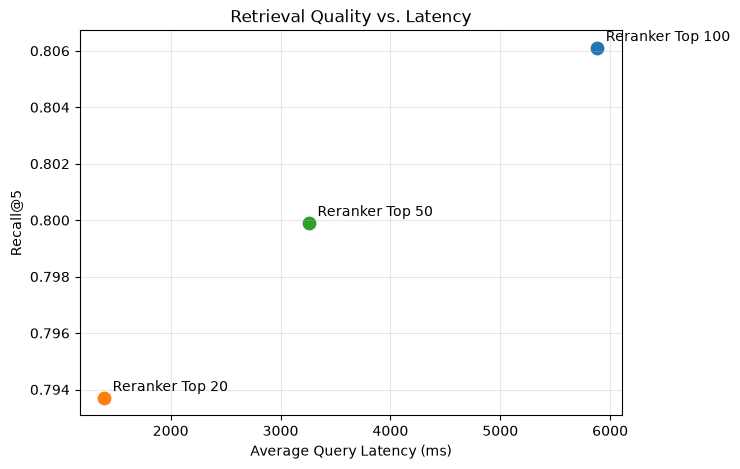

In [172]:
#visualization
plt.figure(figsize=(7, 5))

for name, row in candidate_comparison.iterrows():
    plt.scatter(row["latency_ms"], row["recall@5"], s=80)
    plt.annotate(
        name,
        (row["latency_ms"], row["recall@5"]),
        xytext=(6, 5),
        textcoords="offset points"
    )

plt.xlabel("Average Query Latency (ms)")
plt.ylabel("Recall@5")
plt.title("Retrieval Quality vs. Latency")
plt.grid(alpha=0.3)

# save figure
plt.savefig(
    "results/figures/candidate_pool_optimization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

We investigated the effect of candidate pool size on Cross-Encoder reranking using 20, 50, and 100 candidate documents.

Increasing the candidate pool size improved Recall@5, but also substantially increased retrieval latency. Recall@5 increased from approximately 0.794 with 20 candidates to 0.806 with 100 candidates, while average query latency increased from approximately 1.4 seconds to 5.9 seconds.

These results demonstrate a tradeoff between retrieval effectiveness and computational efficiency. Larger candidate pools improve recall, but the additional gains become relatively small compared with the increase in latency.

The results suggest that smaller candidate pools may be preferable when latency is an important constraint.

#### RRF parameter optimization

goal: how RRF Parameter effects on retrieval quality

In [ ]:
# RRF parameter optimization
rrf_values = [10, 30, 60, 100]
rrf_results = []

for c in rrf_values:
    print(f"Evaluating RRF c={c}...")
    df, rankings = evaluate_retriever(
        f"RRF c={c}",
        lambda q, c=c: hybrid_retrieve(q, k=20, candidate_k=100, c=c),
        dev_queries,
        dev_qrels
    )
    df["rrf_c"] = c
    rrf_results.append(df)

rrf_df = pd.concat(rrf_results, ignore_index=True)
rrf_df.to_csv("results/rrf_optimization.csv", index=False)
print("RRF optimization completed")


Evaluating RRF c=10...
Evaluating RRF c=30...
Evaluating RRF c=60...
Evaluating RRF c=100...
RRF optimization completed!


In [162]:
# performance rrf para optimization comparision
metrics = [ "recall@5", "recall@10", "recall@20", "ndcg@10", "mrr@10", "latency_ms"]
rrf_comparison = (rrf_df.groupby("rrf_c")[metrics].mean().round(4))
display(rrf_comparison)
rrf_comparison.to_csv("results/rrf_comparison.csv")

,recall@5,recall@10,recall@20,ndcg@10,mrr@10,latency_ms
rrf_c,,,,,,
10,0.7459,0.8380,0.9048,0.7012,0.6666,46.7528
30,0.7742,0.8349,0.8987,0.6966,0.6609,53.2051
60,0.7742,0.8287,0.8832,0.6928,0.6576,50.3921
100,0.7711,0.8287,0.8832,0.6921,0.6562,48.1741


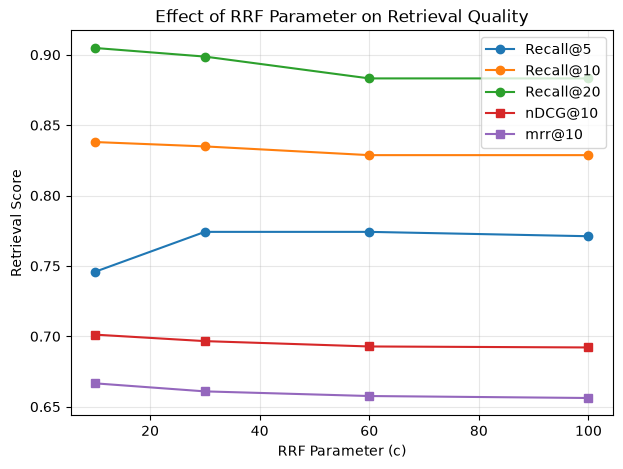

In [174]:
# visualization
plt.figure(figsize=(7, 5))

plt.plot(
    rrf_comparison.index,
    rrf_comparison["recall@5"],
    marker="o",
    label="Recall@5"
)
plt.plot(
    rrf_comparison.index,
    rrf_comparison["recall@10"],
    marker="o",
    label="Recall@10"
)
plt.plot(
    rrf_comparison.index,
    rrf_comparison["recall@20"],
    marker="o",
    label="Recall@20"
)
plt.plot(
    rrf_comparison.index,
    rrf_comparison["ndcg@10"],
    marker="s",
    label="nDCG@10"
)
plt.plot(
    rrf_comparison.index,
    rrf_comparison["mrr@10"],
    marker="s",
    label="mrr@10"
)

plt.xlabel("RRF Parameter (c)")
plt.ylabel("Retrieval Score")
plt.title("Effect of RRF Parameter on Retrieval Quality")
plt.legend()
plt.grid(alpha=0.3)

# save figure
plt.savefig(
    "results/figures/rrf_optimization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [166]:
# choose best rrf c
best_c = rrf_comparison["ndcg@10"].idxmax()

print("Best RRF c:", best_c)
print(rrf_comparison.loc[best_c])

Best RRF c: 10
recall@5       0.7459
recall@10      0.8380
recall@20      0.9048
ndcg@10        0.7012
mrr@10         0.6666
latency_ms    46.7528
Name: 10, dtype: float64


In [175]:
rrf_recall = rrf_df.pivot(
    index="query_id",
    columns="rrf_c",
    values="recall@5"
)

# Compare c=10 and c=30
difference = rrf_recall[10] - rrf_recall[30]

print("\nImproved:", (difference > 0).sum())
print("Worsened:", (difference < 0).sum())
print("Unchanged:", (difference == 0).sum())

worsened_queries = difference[difference < 0]

print("\nNumber of worsened queries:", len(worsened_queries))

for qid in worsened_queries.index[:5]:
    print("\nQuery ID:", qid)
    print("Query:", dev_queries[str(qid)])
    print("Recall@5 c=10:", rrf_recall.loc[qid, 10])
    print("Recall@5 c=30:", rrf_recall.loc[qid, 30])


Improved: 1
Worsened: 7
Unchanged: 154

Number of worsened queries: 7

Query ID: 1075
Query: Sequence conservation in gene regulatory regions between species is a poor predictor of conserved functionality.
Recall@5 c=10: 0.0
Recall@5 c=30: 1.0

Query ID: 1111
Query: Sudden death can occur in patients with complex ventricular arrhythmias.
Recall@5 c=10: 0.0
Recall@5 c=30: 1.0

Query ID: 1325
Query: Treatment with the EC uptake inhibitor AM404 resulted in a dose-dependent decrease in the expression of immobility.
Recall@5 c=10: 0.0
Recall@5 c=30: 1.0

Query ID: 530
Query: Human embryonic stem cells give rise to cell types from the outer embryonic germ layer, but not the other two layers.
Recall@5 c=10: 0.5
Recall@5 c=30: 0.75

Query ID: 541
Query: Hypothalamic glutamate neurotransmission is unrelated to energy balance.
Recall@5 c=10: 0.3333333333333333
Recall@5 c=30: 0.6666666666666666


We investigated the effect of the RRF parameter (c) on hybrid retrieval performance using the SciFact development set. Four values were evaluated: 10, 30, 60, and 100.

The results showed that (c=10) achieved the highest nDCG@10 (0.7012), MRR@10 (0.6666), and Recall@20 (0.9048). However, (c=30) and (c=60) achieved a higher Recall@5 (0.7742) compared with (c=10) (0.7459).

A query-level analysis revealed that changing (c) from 30 to 10 decreased Recall@5 for seven queries, improved it for one query, and left it unchanged for 154 out of 162 queries.

These findings suggest that the RRF parameter affects retrieval quality differently depending on the evaluation metric. Smaller values can improve ranking effectiveness at larger retrieval depths, but may reduce the proportion of relevant documents retrieved within the top five.

Additionally, query latency remained relatively stable across the evaluated parameter values, suggesting that RRF parameter selection has a limited effect on computational cost.

Overall, the results highlight the importance of selecting fusion parameters based on the retrieval system's primary evaluation objective rather than assuming that a single configuration is optimal across all metrics.

#### End-to-End optimization

goal: if cross-encoder reranking doing better by changing rrf c

In [179]:
# end-to-emd optimization
rrf_values = [10, 30, 60]
candidate_k = 50

# create folder end_to_end
opt_dir = Path("results/end_to_end")
opt_dir.mkdir(parents=True, exist_ok=True)

e2e_results = []

for c in rrf_values:
    print(f"Evaluating c={c}, candidate_k={candidate_k}")

    path = opt_dir / f"reranker_c{c}_top{candidate_k}.csv"
    if path.exists():
        df = pd.read_csv(path)
    else:
        df, rankings = evaluate_retriever(
            f"Reranker c={c}",
            lambda q, c=c: rerank_retrieve(q, k=20, candidate_k=candidate_k, c=c),
            dev_queries,
            dev_qrels
        )
        df.to_csv(path, index=False)

    df["rrf_c"] = c
    e2e_results.append(df)

e2e_df = pd.concat(e2e_results, ignore_index=True)

Evaluating c=10, candidate_k=50
Evaluating c=30, candidate_k=50
Evaluating c=60, candidate_k=50


In [180]:
# performance end-to-end optimization comparision
e2e_comparison = (
    e2e_df.groupby("rrf_c")[
        ["recall@5", "recall@10", "recall@20", "ndcg@10", "mrr@10", "latency_ms"]
    ].mean().round(4)
)

display(e2e_comparison)

,recall@5,recall@10,recall@20,ndcg@10,mrr@10,latency_ms
rrf_c,,,,,,
10,0.7999,0.8483,0.9048,0.71,0.6735,3212.9540
30,0.7999,0.8483,0.9048,0.71,0.6735,3149.4005
60,0.7999,0.8483,0.9048,0.71,0.6735,3192.6465


In [ ]:
# check if candidates are same with different rrf c
same_candidates = 0
different_candidates = 0

for qid in dev_qrels:
    query = dev_queries[qid]

    candidates_10 = set(hybrid_retrieve(query, k=50, candidate_k=50, c=10))
    candidates_30 = set(hybrid_retrieve(query, k=50, candidate_k=50, c=30))
    candidates_60 = set(hybrid_retrieve(query, k=50, candidate_k=50, c=60))

    if candidates_10 == candidates_30 == candidates_60:
        same_candidates += 1
    else:
        different_candidates += 1

print("Same candidate sets:", same_candidates)
print("Different candidate sets:", different_candidates)

Same candidate sets: 162
Different candidate sets: 0


We investigated whether optimizing the Reciprocal Rank Fusion (RRF) parameter improves the effectiveness of a hybrid retrieval pipeline with Cross-Encoder reranking.

With the candidate pool size fixed at 50, we evaluated three RRF parameter values: 10, 30, and 60. All configurations achieved identical retrieval metrics, including Recall@5 of 0.7999, nDCG@10 of 0.7100, and MRR@10 of 0.6735.

Further analysis showed that all 162 development queries produced identical sets of the top 50 candidate documents across the three RRF configurations.

Although changing the RRF parameter affected the initial hybrid rankings, it did not change which documents were passed to the Cross-Encoder. Since the reranker independently evaluates query-document relevance, the differences in the initial ranking did not lead to improvements in final retrieval effectiveness.

These findings suggest that RRF parameter optimization may have limited benefits for a Cross-Encoder reranking pipeline when the candidate document set remains unchanged. In contrast, candidate pool size had a more noticeable effect on retrieval quality and computational cost.

## Error analysis: query

reranking failure

In [190]:
# reranking failure

# load evaluation results 
results_df = pd.read_csv("results/all_dev_metrics.csv")
recall_comparison = results_df.pivot(
    index="query_id",
    columns="method",
    values="recall@5"
)
recall_comparison.head()

method,BM25,Dense,Hybrid,Hybrid + Reranker
query_id,,,,
4,0.0,0.0,0.0,0.0
12,1.0,1.0,1.0,1.0
17,0.0,0.0,0.0,0.0
34,1.0,1.0,1.0,1.0
43,1.0,1.0,1.0,1.0


### For recall@5

In [191]:
# calculate recall@5 for every query
recall_comparison["difference"] = (recall_comparison["Hybrid + Reranker"]- recall_comparison["Hybrid"])

improved = recall_comparison[recall_comparison["difference"] > 0]
worsened = recall_comparison[recall_comparison["difference"] < 0]
unchanged = recall_comparison[recall_comparison["difference"] == 0]

print("Improved:", len(improved))
print("Worsened:", len(worsened))
print("Unchanged:", len(unchanged))

# check faquery
failure_cases = worsened.sort_values("difference")
for qid, row in failure_cases.head(5).iterrows():
    print("\nQuery ID:", qid)
    print("Query:", dev_queries[str(qid)])
    print("Hybrid Recall@5:", row["Hybrid"])
    print("Reranker Recall@5:", row["Hybrid + Reranker"])

Improved: 13
Worsened: 8
Unchanged: 141

Query ID: 363
Query: EG7 tumors can be killed by systemic oxaliplatin primed CD8+ T cells from the tumor-draining lymph node cells.
Hybrid Recall@5: 1.0
Reranker Recall@5: 0.0

Query ID: 392
Query: Ethanol stress lowers the expression of PSP in bacteria.
Hybrid Recall@5: 1.0
Reranker Recall@5: 0.0

Query ID: 1209
Query: The deamination of cytidine to uridine on the minus strand of viral DNA can inactivate the viral genome by inducing G-to-A mutations.
Hybrid Recall@5: 1.0
Reranker Recall@5: 0.0

Query ID: 655
Query: Intra-cerebroventricular infusion of amyloid-β oligomers reduces expression of fibronectin type-III domain-containing protein 5 mRNA in mice hippocampi.
Hybrid Recall@5: 1.0
Reranker Recall@5: 0.0

Query ID: 1325
Query: Treatment with the EC uptake inhibitor AM404 resulted in a dose-dependent decrease in the expression of immobility.
Hybrid Recall@5: 1.0
Reranker Recall@5: 0.0


In [185]:
# compare the difference between before reranking and after reranking
with open("results/hybrid_dev_rankings.json", "r", encoding="utf-8"
) as f:
    hybrid_rankings = json.load(f)
with open("results/hybrid_reranker_dev_rankings.json", "r", encoding="utf-8"
) as f:
    reranker_rankings = json.load(f)

filename = name.lower().replace(" + ", "_").replace(" ", "_")

# choose a failure case
target_qid = str(failure_cases.index[0])
relevant_ids = {
    doc_id
    for doc_id, score in dev_qrels[target_qid].items()
    if score > 0
}

print("Query:", dev_queries[target_qid])
print("Relevant documents:", relevant_ids)

for method, rankings in [("Hybrid", hybrid_rankings),("Hybrid + Reranker", reranker_rankings)]:
    print(f"\n{method}")
    
    for rank, doc_id in enumerate(rankings[target_qid][:10], start=1):
        title = corpus[doc_id]["title"]
        print(f"{rank}. {doc_id} "
            f"| Relevant: {doc_id in relevant_ids}"
            f" | {title}"
        )

Query: EG7 tumors can be killed by systemic oxaliplatin primed CD8+ T cells from the tumor-draining lymph node cells.
Relevant documents: {'5386514'}

Hybrid
1. 27567994 | Relevant: False | CD169-positive macrophages dominate antitumor immunity by crosspresenting dead cell-associated antigens.
2. 20610557 | Relevant: False | Alkylating agent melphalan augments the efficacy of adoptive immunotherapy using tumor-specific CD4+ T cells.
3. 15128866 | Relevant: False | CD4+ T cell-mediated cytotoxicity eliminates primary tumor cells in metastatic melanoma through high MHC class II expression and can be enhanced by inhibitory receptor blockade
4. 13231899 | Relevant: False | In situ regulation of DC subsets and T cells mediates tumor regression in mice.
5. 5386514 | Relevant: True | Activation of the NLRP3 inflammasome in dendritic cells induces IL-1β–dependent adaptive immunity against tumors
6. 37444589 | Relevant: False | Apoptosis occurs predominantly in bystander cells and not in produc

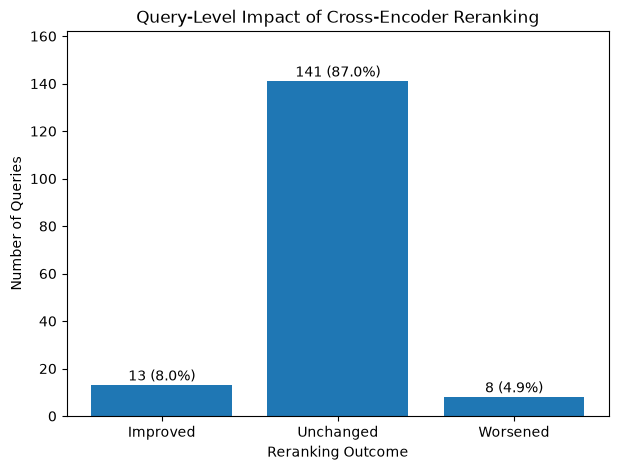

In [187]:
# visualization
counts = {
    "Improved": len(improved),
    "Unchanged": len(unchanged),
    "Worsened": len(worsened)
}

plt.figure(figsize=(7, 5))
bars = plt.bar(counts.keys(), counts.values())
total = sum(counts.values())

for bar, count in zip(bars, counts.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{count} ({count / total:.1%})",
        ha="center"
    )

plt.xlabel("Reranking Outcome")
plt.ylabel("Number of Queries")
plt.title("Query-Level Impact of Cross-Encoder Reranking")
plt.ylim(0, max(counts.values()) * 1.15)

# save figure
plt.savefig(
    fig_dir / "reranking_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Although reranking improved overall retrieval effectiveness, these results demonstrate that the benefits were not consistent across all queries. Some queries experienced substantial performance degradation despite successful retrieval in the initial hybrid stage.

### For ndcg@10

In [192]:
# calculate ndcg@10 for every query
ndcg_comparison = results_df.pivot(
    index="query_id",
    columns="method",
    values="ndcg@10"
)

ndcg_difference = (
    ndcg_comparison["Hybrid + Reranker"]
    - ndcg_comparison["Hybrid"]
)

print("Improved:", (ndcg_difference > 1e-9).sum())
print("Worsened:", (ndcg_difference < -1e-9).sum())
print("Unchanged:", (ndcg_difference.abs() <= 1e-9).sum())

Improved: 38
Worsened: 31
Unchanged: 93


In [193]:
# find querues with improved ndcg@10 and unchanged recall@5
recall_difference = (
    recall_comparison["Hybrid + Reranker"]
    - recall_comparison["Hybrid"]
)

ranking_improved = ((recall_difference.abs() <= 1e-9) & (ndcg_difference > 1e-9))
ranking_worsened = ((recall_difference.abs() <= 1e-9) & (ndcg_difference < -1e-9))

print("Unchanged Recall@5, improved nDCG@10:", ranking_improved.sum())
print("Unchanged Recall@5, worsened nDCG@10:", ranking_worsened.sum())

# find most improvement query
ranking_improvements = (ndcg_difference[ranking_improved].sort_values(ascending=False))

for qid, improvement in ranking_improvements.head(5).items():
    print("\nQuery ID:", qid)
    print("Query:", dev_queries[str(qid)])
    print("nDCG improvement:", round(improvement, 4))

Unchanged Recall@5, improved nDCG@10: 24
Unchanged Recall@5, worsened nDCG@10: 24

Query ID: 1111
Query: Sudden death can occur in patients with complex ventricular arrhythmias.
nDCG improvement: 0.6131

Query ID: 200
Query: CD28 initiates tonic signaling in conventional T cells, which causes an exhaustion phenotype and limited efficiency.
nDCG improvement: 0.5693

Query ID: 1158
Query: The DESMOND program demonstrates no significant impact on lifestyles outcomes.
nDCG improvement: 0.5693

Query ID: 304
Query: DMS3 protein enables Pol V transcription in vivo.
nDCG improvement: 0.5

Query ID: 673
Query: LDL cholesterol has a causal role in the development of cardiovascular disease.
nDCG improvement: 0.3691


In [195]:
# choose query 1111

# the ranking changing for query 1111
target_qid = "1111"
query = dev_queries[target_qid]
relevant_ids = {
    doc_id
    for doc_id, score in dev_qrels[target_qid].items()
    if score > 0
}

hybrid_docs = hybrid_rankings[target_qid]
reranker_docs = reranker_rankings[target_qid]

print("Query:", query)
print("Relevant documents:", relevant_ids)

for doc_id in relevant_ids:
    print("\nDocument ID:", doc_id)
    print("Title:", corpus[doc_id]["title"])
    print("Hybrid Rank:", get_rank(doc_id, hybrid_docs))
    print("Reranker Rank:", get_rank(doc_id, reranker_docs))

#compare top 10
for method, docs in [("Hybrid", hybrid_docs), ("Hybrid + Reranker", reranker_docs)]:
    print(f"\n{method}")

    for rank, doc_id in enumerate(docs[:10], start=1):
        print(
            f"{rank}. {doc_id}"
            f" | Relevant: {doc_id in relevant_ids}"
            f" | {corpus[doc_id]['title']}"
        )

Query: Sudden death can occur in patients with complex ventricular arrhythmias.
Relevant documents: {'1686881'}

Document ID: 1686881
Title: Myocardial muscarinic receptor upregulation and normal response to isoproterenol in denervated hearts by familial amyloid polyneuropathy.
Hybrid Rank: 5
Reranker Rank: 1

Hybrid
1. 26341063 | Relevant: False | Effect of enalapril on 12-year survival and life expectancy in patients with left ventricular systolic dysfunction: a follow-up study.
2. 23117378 | Relevant: False | Sudden infant death syndrome and unclassified sudden infant deaths: a definitional and diagnostic approach.
3. 8509018 | Relevant: False | Diastolic heart failure--abnormalities in active relaxation and passive stiffness of the left ventricle.
4. 21789744 | Relevant: False | Effect of exercise-induced ischemia on QT interval dispersion.
5. 1686881 | Relevant: True | Myocardial muscarinic receptor upregulation and normal response to isoproterenol in denervated hearts by familial

Query 1111 concerns sudden death in patients with complex ventricular arrhythmias. The annotated relevant document (ID: 1686881) was initially ranked fifth by Hybrid Retrieval.

After Cross-Encoder reranking, the relevant document moved from rank 5 to rank 1. As a result, nDCG@10 increased from approximately 0.3869 to 1.0000, an improvement of 0.6131.

However, Recall@5 remained unchanged at 1.0 because the relevant document was already included among the top five results before reranking.

This case demonstrates that Cross-Encoder reranking can substantially improve the positions of relevant documents without changing top-five recall.

When compared with Query 363, where reranking pushed the relevant document outside the top ten, the results illustrate both the benefits and limitations of Cross-Encoder reranking. Although reranking improves overall retrieval effectiveness, its impact varies across individual queries.

## Final test evaluation

Evaluate the retrieval methods using fixed configurations selected during development

In [198]:
# load test set
_, test_queries, test_qrels = GenericDataLoader(
    data_folder="data/scifact"
).load(split="test")

print("Number of test queries:", len(test_qrels))
print("Number of test query texts:", len(test_queries))

test_retrievers = {
    "BM25": lambda q: bm25_retrieve(q, k=20),
    "Dense": lambda q: dense_retrieve(q, k=20),
    "Hybrid": lambda q: hybrid_retrieve(q, k=20, candidate_k=100, c=60),
    "Optimized Hybrid + Reranker": lambda q: rerank_retrieve(q, k=20, candidate_k=50, c=60)
}

  0%|          | 0/5183 [00:00<?, ?it/s]

Number of test queries: 300
Number of test query texts: 300


In [196]:
# create folder final_test
test_dir = Path("results/final_test")
test_dir.mkdir(parents=True, exist_ok=True)

In [199]:
# evaluate final test
all_test_results = []

for name, retrieve_fn in test_retrievers.items():
    filename = name.lower().replace(" + ", "_").replace(" ", "_")
    metrics_path = test_dir / f"{filename}_metrics.csv"
    rankings_path = test_dir / f"{filename}_rankings.json"

    if metrics_path.exists() and rankings_path.exists():
        print(f"Loading {name}...")
        df = pd.read_csv(metrics_path)
        with open(rankings_path, "r", encoding="utf-8") as f:
            rankings = json.load(f)

        assert set(df["query_id"].astype(str)) == set(test_qrels.keys())
        assert set(rankings.keys()) == set(test_qrels.keys())

    else:
        print(f"Evaluating {name}...")
        df, rankings = evaluate_retriever(
            name,
            retrieve_fn,
            test_queries,
            test_qrels
        )
        df.to_csv(metrics_path, index=False)
        with open(rankings_path, "w", encoding="utf-8") as f:
            json.dump(rankings, f, indent=2)

    all_test_results.append(df)
    print(f"Finished {name}")

test_results_df = pd.concat(all_test_results, ignore_index=True)
test_results_df.to_csv(test_dir / "all_test_metrics.csv", index=False)
print("Final Test Evaluation completed")

Evaluating BM25...
Finished BM25
Evaluating Dense...
Finished Dense
Evaluating Hybrid...
Finished Hybrid
Evaluating Optimized Hybrid + Reranker...
Finished Optimized Hybrid + Reranker
Final Test Evaluation completed!


In [200]:
# performance test result
metrics = [ "recall@5", "recall@10", "recall@20", "ndcg@10", "mrr@10", "latency_ms"]
test_comparison = (test_results_df.groupby("method")[metrics].mean().round(4))
display(test_comparison)

,recall@5,recall@10,recall@20,ndcg@10,mrr@10,latency_ms
method,,,,,,
BM25,0.7284,0.7740,0.8323,0.6519,0.6186,31.1024
Dense,0.7379,0.7833,0.8373,0.6451,0.6047,17.0466
Hybrid,0.7395,0.8059,0.8731,0.6816,0.6472,50.5451
Optimized Hybrid + Reranker,0.7482,0.8339,0.8930,0.6976,0.6630,3227.6002


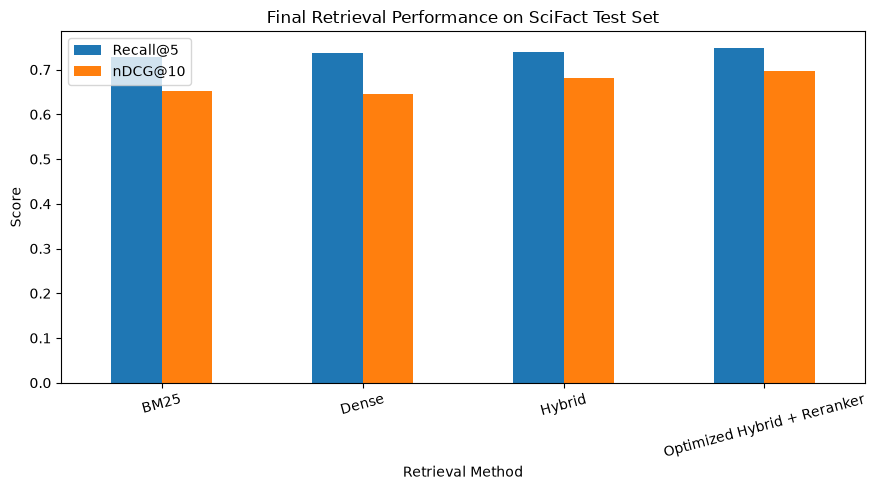

In [201]:
# visualization
plot_df = test_comparison[
    ["recall@5", "ndcg@10"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(9, 5),
    rot=15
)

ax.set_xlabel("Retrieval Method")
ax.set_ylabel("Score")
ax.set_title("Final Retrieval Performance on SciFact Test Set")
ax.legend(["Recall@5", "nDCG@10"])

plt.tight_layout()

# save figure
plt.savefig(
    fig_dir / "final_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

We evaluated four retrieval approaches on the official SciFact test set: BM25, Dense Retrieval, Hybrid Retrieval using Reciprocal Rank Fusion (RRF), and an optimized Hybrid Retrieval pipeline with Cross-Encoder reranking.

The optimized Hybrid + Reranker achieved the highest overall retrieval effectiveness, with Recall@5 of 0.7482, Recall@10 of 0.8339, Recall@20 of 0.8930, nDCG@10 of 0.6976, and MRR@10 of 0.6630.

Hybrid Retrieval outperformed the individual BM25 and Dense approaches across all five effectiveness metrics. Adding Cross-Encoder reranking further improved retrieval quality, increasing nDCG@10 from 0.6816 to 0.6976.

However, these gains came at a considerable computational cost. Average query latency increased from approximately 50.55 milliseconds for Hybrid Retrieval to 3.23 seconds for the optimized reranking pipeline.

Compared with development-set results, the optimized reranking pipeline showed lower Recall@5 on the test set (0.7482 versus 0.7999). Nevertheless, the relative advantage of reranking over Hybrid Retrieval was preserved.

Overall, the results demonstrate that combining lexical and semantic retrieval improves retrieval effectiveness, while Cross-Encoder reranking offers additional gains at a substantial latency cost. Candidate pool optimization provides a practical way to balance retrieval quality and computational efficiency.